# Paper-LSTM Training

Kompakter End-to-End-Ablauf: Daten laden, Sequenzen bauen, Paper-LSTM trainieren und gegen Persistence vergleichen.

In [6]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from train_weather_rnn import Config, train
from weather_dataloader import make_weather_dataloaders

PROJECT_ROOT

PosixPath('/Users/thomasgaillinger/Documents/Master/Projekt_1/XAI-timeseries')

## Daten pruefen

Feature-Legende:

| Feature | Bedeutung |
|---|---|
| `TT_TU` | Tagesmittel der Lufttemperatur [C] |
| `RF_TU` | Tagesmittel der relativen Luftfeuchte [%] |
| `R1` | Tagessumme des Niederschlags [mm] |
| `SD_SO` | Tagessumme der Sonnenscheindauer |
| `F` | Tagesmittel der Windgeschwindigkeit [m/s] |
| `P0` | Tagesmittel des Luftdrucks auf Stationshoehe [hPa] |
| `day_sin` | Sinus-Codierung des Tags im Jahr, bildet Saisonalitaet ab |
| `day_cos` | Cosinus-Codierung des Tags im Jahr, bildet Saisonalitaet ab |

In [7]:
cfg = Config(
    data_path=str(PROJECT_ROOT / "data" / "processed" / "weather_clean_daily.csv"),
    output_dir=str(PROJECT_ROOT / "outputs" / "rnn_weather_paper_lstm"),
    device="auto",  # Uses Apple MPS if available, otherwise CUDA, otherwise CPU.
)

data = make_weather_dataloaders(
    data_path=cfg.data_path,
    target=cfg.target,
    sequence_length=cfg.sequence_length,
    horizon=cfg.horizon,
    batch_size=cfg.batch_size,
    train_until=cfg.train_until,
    val_until=cfg.val_until,
    add_engineered_features=cfg.add_engineered_features,
)

x_batch, y_batch, dates = next(iter(data.train_loader))
print("Features:", data.feature_columns)
print("Train/Val/Test:", data.train_samples, data.val_samples, data.test_samples)
print("Batch X:", tuple(x_batch.shape), "Batch y:", tuple(y_batch.shape))
data.dataframe.head()

Features: ['TT_TU', 'RF_TU', 'R1', 'SD_SO', 'F', 'P0', 'day_sin', 'day_cos']
Train/Val/Test: 2509 730 366
Batch X: (64, 48, 8) Batch y: (64, 1)


,TT_TU,RF_TU,R1,SD_SO,F,P0,day_sin,day_cos
datetime,,,,,,,,
2015-01-01,0.066667,97.333333,0.2,0.0,1.687500,991.104167,0.017202,0.999852
2015-01-02,-0.458333,94.833333,3.6,0.0,3.191667,986.570833,0.034398,0.999408
2015-01-03,0.841667,93.125000,13.2,0.0,2.554167,980.654167,0.051584,0.998669
2015-01-04,1.100000,88.833333,0.6,26.0,5.154167,983.175000,0.068755,0.997634
2015-01-05,0.670833,82.625000,0.0,37.0,3.012500,986.725000,0.085906,0.996303


## Trainieren

In [8]:
metrics = train(cfg)
pd.Series(metrics)

epoch=001 train_loss=0.5568 val_loss=0.1917
epoch=002 train_loss=0.1742 val_loss=0.0921
epoch=003 train_loss=0.1290 val_loss=0.0788
epoch=004 train_loss=0.1169 val_loss=0.0833
epoch=005 train_loss=0.1079 val_loss=0.0726
epoch=006 train_loss=0.1049 val_loss=0.0768
epoch=007 train_loss=0.0947 val_loss=0.0678
epoch=008 train_loss=0.0922 val_loss=0.0773
epoch=009 train_loss=0.0874 val_loss=0.0633
epoch=010 train_loss=0.0843 val_loss=0.0636
epoch=011 train_loss=0.0800 val_loss=0.0609
epoch=012 train_loss=0.0809 val_loss=0.0605
epoch=013 train_loss=0.0773 val_loss=0.0670
epoch=014 train_loss=0.0753 val_loss=0.0632
epoch=015 train_loss=0.0709 val_loss=0.0593
epoch=016 train_loss=0.0737 val_loss=0.0671
epoch=017 train_loss=0.0681 val_loss=0.0634
epoch=018 train_loss=0.0701 val_loss=0.0643
epoch=019 train_loss=0.0748 val_loss=0.0664
epoch=020 train_loss=0.0655 val_loss=0.0610
epoch=021 train_loss=0.0675 val_loss=0.0599
epoch=022 train_loss=0.0685 val_loss=0.0576
epoch=023 train_loss=0.0636 val_

best_epoch                                                                22
model                                                             paper_lstm
target                                                                 TT_TU
sequence_length                                                           48
horizon                                                                    1
hidden_size                                                               64
num_layers                                                                 2
dropout                                                                 0.15
batch_size                                                                64
epochs                                                                    80
learning_rate                                                          0.001
weight_decay                                                          0.0001
patience                                                                  12

## Evaluation

In [9]:
output_dir = Path(cfg.output_dir)
history = pd.read_csv(output_dir / "history.csv")
predictions = pd.read_csv(output_dir / "test_predictions.csv", parse_dates=["datetime"])

comparison = pd.DataFrame(
    [
        {"model": "Paper-LSTM", "RMSE": metrics["test_rmse"], "MAE": metrics["test_mae"]},
        {"model": "Persistence", "RMSE": metrics["persistence_test_rmse"], "MAE": metrics["persistence_test_mae"]},
    ]
)
display(comparison.round(3))

improvement = (metrics["persistence_test_rmse"] - metrics["test_rmse"]) / metrics["persistence_test_rmse"] * 100
print(f"RMSE improvement vs. persistence: {improvement:.1f}%")

,model,RMSE,MAE
0,Paper-LSTM,1.914,1.533
1,Persistence,2.116,1.642


RMSE improvement vs. persistence: 9.6%


## Plots

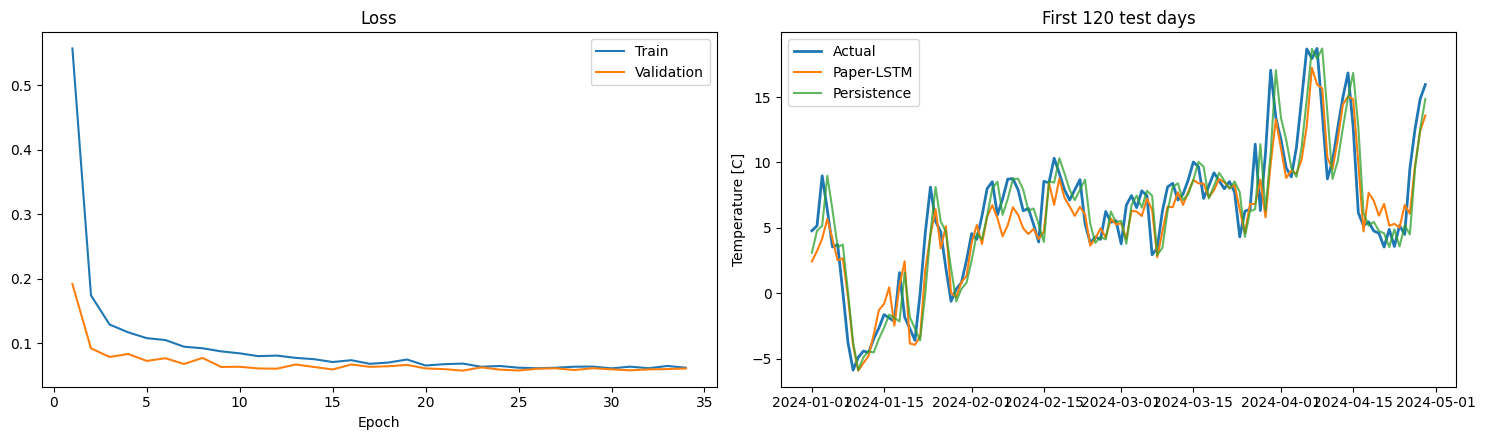

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

axes[0].plot(history["epoch"], history["train_loss"], label="Train")
axes[0].plot(history["epoch"], history["val_loss"], label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

focus = predictions.head(120)
axes[1].plot(focus["datetime"], focus["actual"], label="Actual", linewidth=2)
axes[1].plot(focus["datetime"], focus["prediction"], label="Paper-LSTM")
axes[1].plot(focus["datetime"], focus["persistence"], label="Persistence", alpha=0.75)
axes[1].set_title("First 120 test days")
axes[1].set_ylabel("Temperature [C]")
axes[1].legend()

plt.tight_layout()